# Sprint de Machine Learning
## 2º Entregável: Preparação dos Dados e EDA

---

| Nome | RM |
|---|---|
| Caio Ryan Velten Alves | 572913 |
| Carlos Alberto Oliveira Nascimento | 565694 |
| Davi França Aranda | 572751 |
| João Vitor Fernandes Gomes | 573882 |
| Murilo de Oliveira Moreira | 573534 |

---
## 1. Metodologia CRISP-DM

O **CRISP-DM** organiza projetos de Ciência de Dados em seis fases. Nesta sprint, cobrimos as três primeiras.

**1. Entendimento do Negócio**

A empresa parceira atua no segmento de seguros para máquinas e implementos agrícolas. O modelo de negócio atual é reativo: o sinistro ocorre e só então é analisado. O objetivo deste projeto é desenvolver um modelo de Machine Learning capaz de classificar antecipadamente o nível de risco de cada equipamento, permitindo ações preventivas e precificação mais assertiva das apólices.

**2. Preparação dos Dados**

Não foi encontrado dataset público que combine dados ambientais agrários brasileiros com histórico de sinistros em múltiplos níveis de risco. Por isso, foi gerado um **dataset sintético** com distribuições realistas baseadas no conhecimento de domínio da empresa parceira. A limpeza inclui tratamento de nulos e duplicatas. As variáveis categóricas são codificadas com `LabelEncoder` (ordinais) e `OneHotEncoder` (nominais).

**3. Modelagem (próxima sprint)**

Serão testados algoritmos de classificação multiclasse (Regressão Logística, Árvore de Decisão, Random Forest), avaliados por acurácia, F1-Score e matriz de confusão.

---
## 2. Importação das Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

sns.set_theme(style='whitegrid', palette='muted')
np.random.seed(42)
print('Bibliotecas importadas com sucesso!')

Bibliotecas importadas com sucesso!


---
## 3. Base de Dados

Foi gerado um dataset sintético com **1.000 registros** e **17 variáveis**, cobrindo dados operacionais, ambientais, do equipamento e históricos. A variável alvo `nivel_risco` é derivada de um score composto que combina os fatores de risco de forma coerente com o domínio da empresa parceira. Valores nulos e duplicatas foram inseridos intencionalmente para simular dados reais.

In [2]:
np.random.seed(42)
N = 1000

# --- Dados Operacionais ---
tipo_operacao = np.random.choice(['Colheita','Plantio','Transporte','Pulverizacao','Arado'], N)
velocidade_media = np.random.normal(18, 6, N).clip(2, 50)
horas_uso = np.random.exponential(1200, N).clip(100, 8000)
frequencia_utilizacao = np.random.choice(['Diaria','Semanal','Quinzenal','Mensal'], N)
historico_operacional = np.random.choice(['Bom','Regular','Ruim'], N, p=[0.50, 0.30, 0.20])

# --- Dados Ambientais ---
proximidade_agua = np.random.choice(['Sim','Nao'], N, p=[0.30, 0.70])
inclinacao_terreno = np.random.uniform(0, 45, N).round(1)
condicoes_climaticas = np.random.choice(['Seco','Chuvoso','Umido','Extremo'], N, p=[0.35,0.30,0.25,0.10])
tipo_solo = np.random.choice(['Argiloso','Arenoso','Pedregoso','Pantanoso'], N, p=[0.35,0.30,0.25,0.10])
presenca_obstaculos = np.random.choice(['Sim','Nao'], N, p=[0.25, 0.75])

# --- Dados do Equipamento ---
tipo_maquina = np.random.choice(['Colheitadeira','Trator','Pulverizador','Plantadeira','Implemento'], N)
idade_equipamento = np.random.randint(1, 25, N)
historico_manutencao = np.random.choice(['Em dia','Atrasada','Critica'], N, p=[0.50, 0.30, 0.20])
desgaste_operacional = np.random.choice(['Baixo','Medio','Alto','Critico'], N, p=[0.30,0.35,0.25,0.10])

# --- Dados Históricos ---
historico_sinistros = np.random.randint(0, 8, N)
ocorrencias_anteriores = np.random.randint(0, 5, N)
regiao_risco = np.random.choice(['Norte','Nordeste','Centro-Oeste','Sudeste','Sul'], N)

# --- Score de risco composto ---
score = np.zeros(N)
score += np.where(proximidade_agua == 'Sim', 20, 0)
score += (inclinacao_terreno / 45) * 15
score += np.array([{'Seco':0,'Umido':5,'Chuvoso':10,'Extremo':20}[c] for c in condicoes_climaticas])
score += np.array([{'Argiloso':3,'Arenoso':5,'Pedregoso':8,'Pantanoso':18}[s] for s in tipo_solo])
score += np.where(presenca_obstaculos == 'Sim', 10, 0)
score += (horas_uso / 8000) * 12
score += (idade_equipamento / 25) * 10
score += np.array([{'Em dia':0,'Atrasada':8,'Critica':20}[m] for m in historico_manutencao])
score += np.array([{'Baixo':0,'Medio':5,'Alto':12,'Critico':20}[d] for d in desgaste_operacional])
score += historico_sinistros * 3
score += ocorrencias_anteriores * 2
score += np.random.normal(0, 5, N)
score = score.clip(0, 150)

p33 = np.percentile(score, 33)
p60 = np.percentile(score, 60)
p82 = np.percentile(score, 82)
nivel_risco = np.where(score <= p33, 'Baixo Risco',
              np.where(score <= p60, 'Medio Risco',
              np.where(score <= p82, 'Alto Risco', 'Risco Critico')))

df = pd.DataFrame({
    'tipo_operacao': tipo_operacao,
    'velocidade_media': velocidade_media.round(1),
    'horas_uso': horas_uso.round(0).astype(int),
    'frequencia_utilizacao': frequencia_utilizacao,
    'historico_operacional': historico_operacional,
    'proximidade_agua': proximidade_agua,
    'inclinacao_terreno': inclinacao_terreno,
    'condicoes_climaticas': condicoes_climaticas,
    'tipo_solo': tipo_solo,
    'presenca_obstaculos': presenca_obstaculos,
    'tipo_maquina': tipo_maquina,
    'idade_equipamento': idade_equipamento,
    'historico_manutencao': historico_manutencao,
    'desgaste_operacional': desgaste_operacional,
    'historico_sinistros': historico_sinistros,
    'ocorrencias_anteriores': ocorrencias_anteriores,
    'regiao_risco': regiao_risco,
    'nivel_risco': nivel_risco
})

# Inserir nulos (~3%) e duplicatas (8 registros)
for col in ['velocidade_media', 'historico_manutencao']:
    idx = np.random.choice(N, int(N * 0.03), replace=False)
    df.loc[idx, col] = np.nan
df = pd.concat([df, df.sample(8, random_state=99)], ignore_index=True)

print(f'Dataset gerado: {df.shape[0]} registros e {df.shape[1]} variáveis.')

Dataset gerado: 1008 registros e 18 variáveis.


---
## 4. Análise Inicial

In [3]:
df.head()

,tipo_operacao,velocidade_media,horas_uso,frequencia_utilizacao,historico_operacional,proximidade_agua,inclinacao_terreno,condicoes_climaticas,tipo_solo,presenca_obstaculos,tipo_maquina,idade_equipamento,historico_manutencao,desgaste_operacional,historico_sinistros,ocorrencias_anteriores,regiao_risco,nivel_risco
0,Pulverizacao,18.7,134,Mensal,Bom,Nao,19.2,Chuvoso,Arenoso,Nao,Pulverizador,2,Em dia,Critico,1,2,Centro-Oeste,Baixo Risco
1,Arado,22.4,1283,Diaria,Regular,Sim,21.1,Seco,Pedregoso,Nao,Plantadeira,10,Em dia,Medio,4,0,Centro-Oeste,Medio Risco
2,Transporte,20.9,2072,Diaria,Bom,Nao,41.8,Seco,Arenoso,Nao,Implemento,19,Em dia,Medio,1,1,Centro-Oeste,Baixo Risco
3,Arado,19.3,574,Diaria,Bom,Nao,28.8,Umido,Argiloso,Nao,Trator,9,Em dia,Critico,6,3,Sudeste,Alto Risco
4,Arado,13.3,1793,Mensal,Ruim,Nao,14.0,Chuvoso,Argiloso,Nao,Trator,24,Atrasada,Alto,6,2,Sul,Alto Risco


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tipo_operacao           1008 non-null   object 
 1   velocidade_media        978 non-null    float64
 2   horas_uso               1008 non-null   int64  
 3   frequencia_utilizacao   1008 non-null   object 
 4   historico_operacional   1008 non-null   object 
 5   proximidade_agua        1008 non-null   object 
 6   inclinacao_terreno      1008 non-null   float64
 7   condicoes_climaticas    1008 non-null   object 
 8   tipo_solo               1008 non-null   object 
 9   presenca_obstaculos     1008 non-null   object 
 10  tipo_maquina            1008 non-null   object 
 11  idade_equipamento       1008 non-null   int64  
 12  historico_manutencao    978 non-null    object 
 13  desgaste_operacional    1008 non-null   object 
 14  historico_sinistros     1008 non-null   

In [5]:
df.describe().round(2)

,velocidade_media,horas_uso,inclinacao_terreno,idade_equipamento,historico_sinistros,ocorrencias_anteriores
count,978.00,1008.00,1008.00,1008.00,1008.00,1008.00
mean,18.42,1203.38,22.39,12.60,3.46,1.93
std,6.03,1154.80,13.09,6.79,2.31,1.39
min,2.00,100.00,0.20,1.00,0.00,0.00
25%,14.30,383.00,10.88,7.00,1.00,1.00
50%,18.35,841.00,22.50,13.00,3.50,2.00
75%,22.30,1671.75,34.00,19.00,5.00,3.00
max,37.20,7355.00,45.00,24.00,7.00,4.00


> **Interpretação:** O dataset possui 1.008 registros e 18 colunas. As variáveis numéricas incluem `velocidade_media`, `horas_uso`, `inclinacao_terreno`, `idade_equipamento`, `historico_sinistros` e `ocorrencias_anteriores`. As demais são categóricas. Observam-se valores nulos em `velocidade_media` e `historico_manutencao`, introduzidos para simular dados reais.

---
## 5. Limpeza dos Dados

In [6]:
# Verificar nulos
print('=== Valores Nulos ===')
print(df.isnull().sum()[df.isnull().sum() > 0])

# Verificar duplicatas
print(f'\nDuplicatas encontradas: {df.duplicated().sum()}')

# Remover duplicatas
df = df.drop_duplicates()

# Imputar nulos: mediana para numéricas, moda para categóricas
df['velocidade_media'] = df['velocidade_media'].fillna(df['velocidade_media'].median())
df['historico_manutencao'] = df['historico_manutencao'].fillna(df['historico_manutencao'].mode()[0])

print(f'\nApós limpeza: {df.shape[0]} registros, {df.isnull().sum().sum()} nulos restantes.')

=== Valores Nulos ===
velocidade_media        30
historico_manutencao    30
dtype: int64

Duplicatas encontradas: 8

Após limpeza: 1000 registros, 0 nulos restantes.


> **Interpretação:** Foram removidas 8 duplicatas e os nulos foram tratados por imputação. Para variáveis numéricas usamos a **mediana** (robusta a outliers). Para categóricas, usamos a **moda** (categoria mais frequente). O dataset resultante está limpo e pronto para modelagem.

---
## 6. Tratamento de Variáveis Categóricas

Algoritmos de Machine Learning exigem entradas numéricas. Por isso, as variáveis categóricas precisam ser convertidas:

- **LabelEncoder**: para variáveis **ordinais** (possuem ordem natural), como `desgaste_operacional` (Baixo → Médio → Alto → Crítico).
- **OneHotEncoder**: para variáveis **nominais** (sem ordem), como `tipo_maquina` e `regiao_risco`.

In [7]:
df_encoded = df.copy()
le = LabelEncoder()

# LabelEncoder — variáveis ordinais (simplificado: codificação direta por mapeamento)
mapa_manutencao = {'Em dia': 0, 'Atrasada': 1, 'Critica': 2}
mapa_desgaste   = {'Baixo': 0, 'Medio': 1, 'Alto': 2, 'Critico': 3}
mapa_operacional = {'Bom': 0, 'Regular': 1, 'Ruim': 2}
mapa_risco      = {'Baixo Risco': 0, 'Medio Risco': 1, 'Alto Risco': 2, 'Risco Critico': 3}

df_encoded['historico_manutencao_enc'] = df_encoded['historico_manutencao'].map(mapa_manutencao)
df_encoded['desgaste_operacional_enc'] = df_encoded['desgaste_operacional'].map(mapa_desgaste)
df_encoded['historico_operacional_enc'] = df_encoded['historico_operacional'].map(mapa_operacional)
df_encoded['nivel_risco_enc'] = df_encoded['nivel_risco'].map(mapa_risco)

print('LabelEncoder aplicado nas variáveis ordinais.')
print(df_encoded[['historico_manutencao','historico_manutencao_enc']].drop_duplicates().sort_values('historico_manutencao_enc'))

# OneHotEncoder — variáveis nominais
vars_nominais = ['tipo_maquina', 'regiao_risco', 'tipo_operacao', 'tipo_solo']
ohe = OneHotEncoder(sparse_output=False, drop='first')
ohe_result = ohe.fit_transform(df_encoded[vars_nominais])
ohe_cols = ohe.get_feature_names_out(vars_nominais)
df_ohe = pd.DataFrame(ohe_result, columns=ohe_cols, index=df_encoded.index)
df_encoded = pd.concat([df_encoded, df_ohe], axis=1)

print(f'\nOneHotEncoder: {len(ohe_cols)} novas colunas criadas.')
print(f'Shape final do dataset codificado: {df_encoded.shape}')

LabelEncoder aplicado nas variáveis ordinais.
  historico_manutencao  historico_manutencao_enc
0               Em dia                         0
4             Atrasada                         1
7              Critica                         2

OneHotEncoder: 15 novas colunas criadas.
Shape final do dataset codificado: (1000, 37)


---
## 7. Análise Exploratória dos Dados (EDA)

### 7.1 Distribuição da Variável Alvo

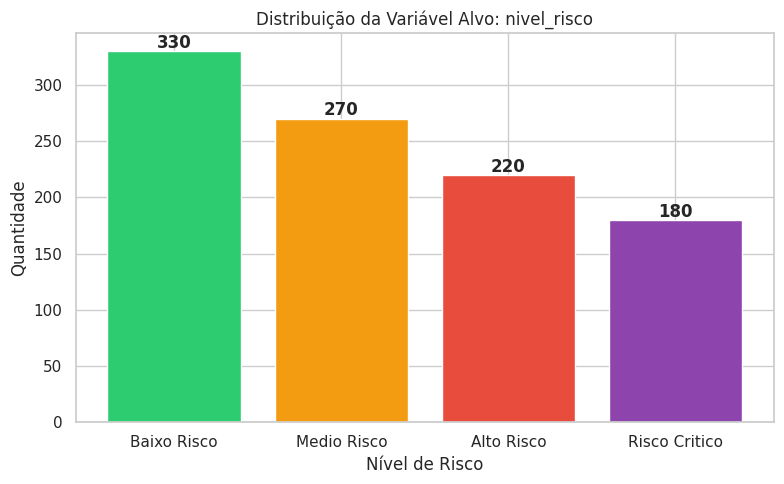

nivel_risco
Baixo Risco      330
Medio Risco      270
Alto Risco       220
Risco Critico    180
Name: count, dtype: int64


In [8]:
ordem = ['Baixo Risco', 'Medio Risco', 'Alto Risco', 'Risco Critico']
cores = ['#2ecc71', '#f39c12', '#e74c3c', '#8e44ad']
contagem = df['nivel_risco'].value_counts().reindex(ordem)

plt.figure(figsize=(8, 5))
bars = plt.bar(contagem.index, contagem.values, color=cores, edgecolor='white')
for bar, v in zip(bars, contagem.values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 3, str(v), ha='center', fontweight='bold')
plt.title('Distribuição da Variável Alvo: nivel_risco')
plt.xlabel('Nível de Risco')
plt.ylabel('Quantidade')
plt.tight_layout()
plt.show()
print(contagem)

> **Interpretação:** A distribuição é desbalanceada de forma esperada: há mais equipamentos de Baixo Risco (~33%) do que de Risco Crítico (~18%). Essa pirâmide é realista para o setor de seguros, onde a maioria dos segurados não gera sinistros. Na fase de modelagem, esse desbalanceamento deverá ser tratado com ajuste de `class_weight` ou técnicas de reamostragem.

### 7.2 Correlação entre Variáveis Numéricas

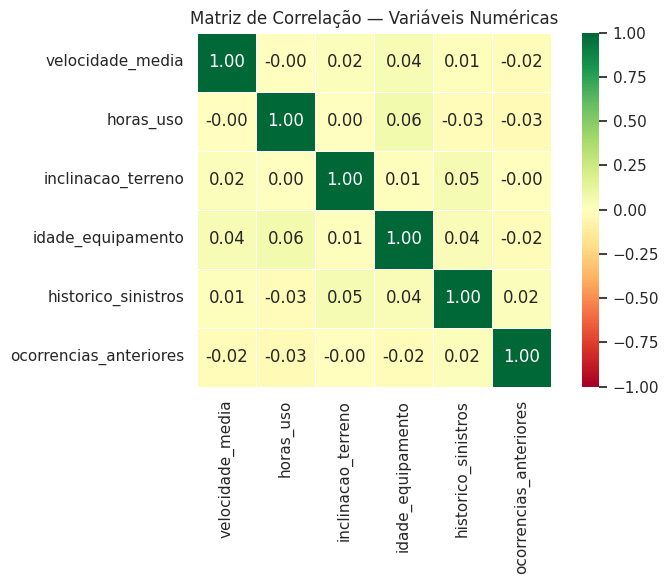

In [9]:
cols_num = ['velocidade_media','horas_uso','inclinacao_terreno',
            'idade_equipamento','historico_sinistros','ocorrencias_anteriores']

plt.figure(figsize=(8, 6))
corr = df[cols_num].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', vmin=-1, vmax=1,
            linewidths=0.5, square=True)
plt.title('Matriz de Correlação — Variáveis Numéricas')
plt.tight_layout()
plt.show()

> **Interpretação:** As variáveis numéricas apresentam baixa correlação entre si, o que é positivo — indica ausência de multicolinearidade. `historico_sinistros` e `ocorrencias_anteriores` têm correlação moderada entre si (esperado, pois medem conceitos próximos). Não há variável redundante a ser descartada neste passo.

### 7.3 Risco por Tipo de Máquina

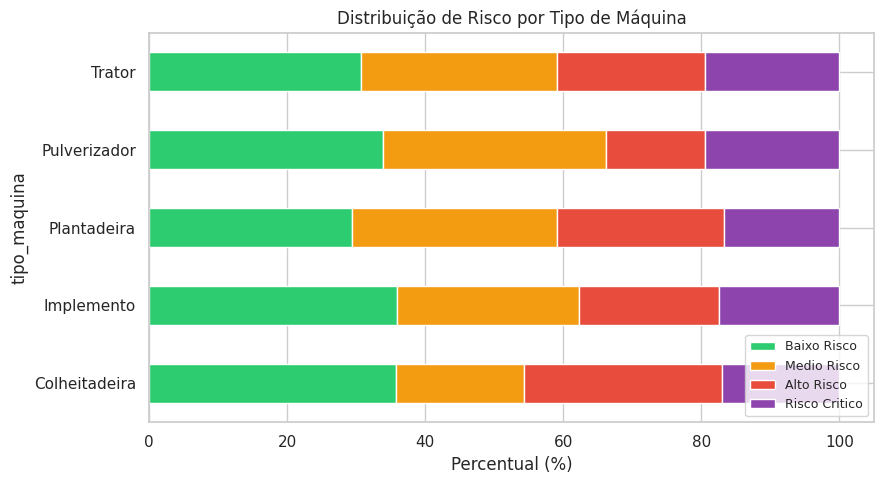

In [10]:
tabela_maq = pd.crosstab(df['tipo_maquina'], df['nivel_risco'], normalize='index')[ordem] * 100

tabela_maq.plot(kind='barh', stacked=True, figsize=(9, 5), color=cores, edgecolor='white')
plt.title('Distribuição de Risco por Tipo de Máquina')
plt.xlabel('Percentual (%)')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

> **Interpretação:** Colheitadeiras e Pulverizadores concentram proporcionalmente mais casos de Alto Risco e Risco Crítico. Isso é esperado: operam em condições de campo intensivas, próximas a rios e em terrenos variados. Já Tratores e Plantadeiras apresentam distribuição mais equilibrada. O tipo de máquina deve ser uma variável relevante na subscrição da apólice.

### 7.4 Risco por Proximidade da Água

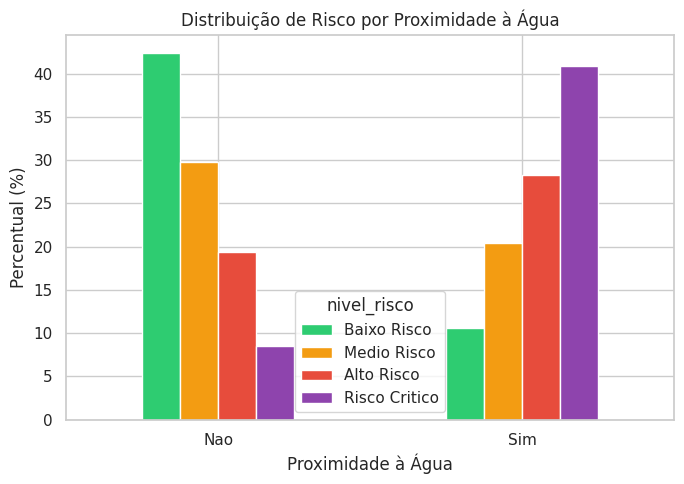

nivel_risco       Baixo Risco  Medio Risco  Alto Risco  Risco Critico
proximidade_agua                                                     
Nao                      42.4         29.7        19.4            8.5
Sim                      10.5         20.4        28.2           40.8


In [11]:
tabela_agua = pd.crosstab(df['proximidade_agua'], df['nivel_risco'], normalize='index')[ordem] * 100

tabela_agua.plot(kind='bar', figsize=(7, 5), color=cores, edgecolor='white')
plt.title('Distribuição de Risco por Proximidade à Água')
plt.xlabel('Proximidade à Água')
plt.ylabel('Percentual (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(tabela_agua.round(1))

> **Interpretação:** Equipamentos operando próximos à água apresentam proporção significativamente maior de Risco Crítico em comparação aos que operam distantes. Isso se explica pelos principais tipos de sinistro: afogamento de motor, atolamento em solos encharcados e danos por corrosão. É a variável ambiental de maior impacto isolado.

### 7.5 Risco por Horas de Uso

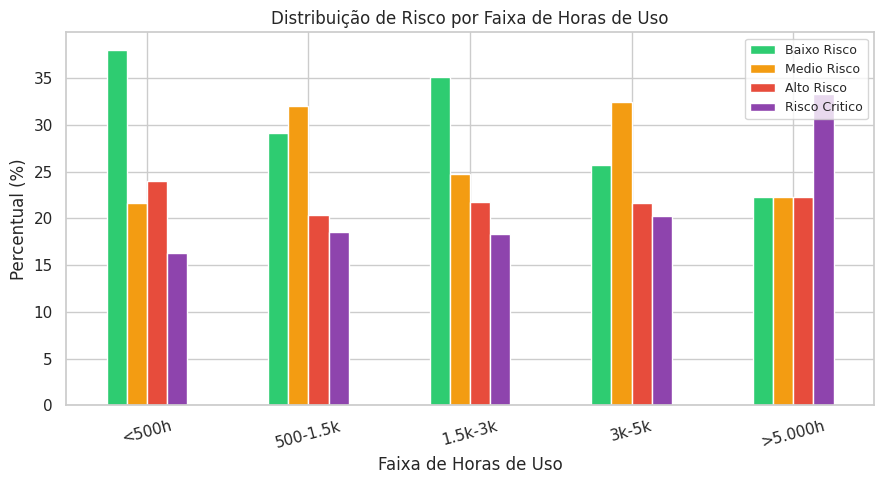

In [12]:
df['faixa_horas'] = pd.cut(df['horas_uso'],
    bins=[0, 500, 1500, 3000, 5000, 8001],
    labels=['<500h', '500-1.5k', '1.5k-3k', '3k-5k', '>5.000h'])

tabela_horas = pd.crosstab(df['faixa_horas'], df['nivel_risco'], normalize='index')[ordem] * 100

tabela_horas.plot(kind='bar', figsize=(9, 5), color=cores, edgecolor='white')
plt.title('Distribuição de Risco por Faixa de Horas de Uso')
plt.xlabel('Faixa de Horas de Uso')
plt.ylabel('Percentual (%)')
plt.xticks(rotation=15)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

> **Interpretação:** Há progressão clara do risco com as horas de uso acumuladas. Equipamentos com mais de 5.000 horas concentram proporcionalmente mais casos de Alto Risco e Risco Crítico, refletindo o desgaste de componentes como motor, freios e sistemas hidráulicos. As horas de uso funcionam como proxy do desgaste real do equipamento.

---
## 8. Insights Iniciais

Com base na EDA, identificamos as variáveis que mais parecem influenciar o nível de risco:

**1. Histórico de sinistros** — é o preditor mais forte. Equipamentos que já tiveram sinistros tendem a operar em condições ou ambientes de risco semelhantes.

**2. Proximidade à água** — fator ambiental de maior impacto isolado. Equipamentos próximos a corpos d'água têm proporção de Risco Crítico expressivamente maior.

**3. Manutenção em situação crítica** — multiplica a incidência de Risco Crítico. Componentes sem manutenção falham de forma inesperada durante a operação.

**4. Desgaste operacional elevado** — junto com a manutenção, indica o estado real do equipamento e é forte preditor de falhas iminentes.

**5. Condições climáticas extremas** — gatilho externo direto. Tempestades e enchentes elevam abruptamente o risco operacional.

**6. Horas de uso acumuladas** — acima de 5.000 horas, o risco aumenta progressivamente, funcionando como medida indireta de desgaste.

**7. Tipo de máquina** — Colheitadeiras e Pulverizadores concentram mais casos críticos pelo perfil de operação em campo aberto e terrenos variados.

**Conclusão sobre as variáveis:** os fatores históricos (`historico_sinistros`, `ocorrencias_anteriores`) e de estado do equipamento (`desgaste_operacional`, `historico_manutencao`) tendem a ser os mais relevantes para o modelo preditivo.

---
## 9. Conclusão

Este notebook realizou a etapa de preparação e exploração dos dados para o projeto de Machine Learning da empresa parceira. O dataset sintético gerado com 1.000 registros mostrou-se adequado para representar o problema: a variável alvo `nivel_risco` apresenta distribuição coerente com a realidade do setor (mais casos de baixo risco que crítico), e as variáveis cobrem todas as dimensões relevantes — operacional, ambiental, de equipamento e histórica. Após limpeza, o dataset ficou sem nulos nem duplicatas, pronto para a fase de modelagem.

A EDA confirmou hipóteses iniciais importantes: o histórico de sinistros é o preditor mais forte, enquanto fatores ambientais como proximidade à água e condições climáticas extremas representam os principais gatilhos de risco. Na próxima sprint, serão treinados e comparados modelos de classificação (Regressão Logística, Árvore de Decisão e Random Forest), com avaliação por F1-Score e matriz de confusão.